# CNN Baseline from Scratch

### Objective

Establish a baseline for binary chest X-ray classification using a small CNN trained from randomly initialised weights.

This experiment serves as a comparison point for the subsequent ImageNet-pretrained ResNet18 model.

### Model Design

A lightweight CNN with 3 convolutional layers, followed by a classification output layer. 

### Experimental Approach
- Train from scratch without pretrained weights
- Use existing preprocessing pipeline and patient-level dataset splits
- Keep architecture and training process simple, without extensive hyperparameter experimentation
- Record training time and validation metrics

The results will be compared against ResNet18 to investigate the contribution of ImageNet pretraining to classification performance.

## 01. Set Up Notebook

In [1]:
# Standard library
import random
import sys
from pathlib import Path

# Data and visualisation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Project source code
cwd = Path.cwd().resolve()
PROJECT_DIR = next((path for path in [cwd, *cwd.parents]
                    if path.name == "transfer-learning-resnet"
                    and (path / "src" / "data_loader.py").exists()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Count not locate project directory.")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.data_loader import ChestXrayDataset
from src.transforms import get_preprocessing_transform

# Paths
DATA_DIR = PROJECT_DIR.parent / "data"
IMAGE_DIR = DATA_DIR / "raw" / "images"
CSV_PATH = DATA_DIR / "processed" / "mlp_dataset.csv"

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device
if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print("Project directory:", PROJECT_DIR)  
print("Device:", DEVICE)
print("PyTorch version:", torch.__version__)          

Project directory: /Users/hweeenheah/Downloads/EDA_Resources/nih-chestxray-ml/transfer-learning-resnet
Device: mps
PyTorch version: 2.15.0


## 02. Recreate DataLoaders

In [2]:
preprocess_transform = get_preprocessing_transform()

train_dataset = ChestXrayDataset(CSV_PATH, IMAGE_DIR, preprocess_transform, split="train")
val_dataset = ChestXrayDataset(CSV_PATH, IMAGE_DIR, preprocess_transform, split="val")
test_dataset = ChestXrayDataset(CSV_PATH, IMAGE_DIR, preprocess_transform, split="test")

BATCH_SIZE = 32

generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 2208
Validation: 554
Test: 479


## 03. Define scratch CNN architecture

### 3.1 Simple CNN architecture with 3 convolutional layers

In [3]:
class ScratchCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            # Conv layer 1
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # Conv layer 2
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # Conv layer 3
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2))
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Linear(64, 1)
    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x        

### 3.2 Instantiate and inspect model

In [4]:
model = ScratchCNN().to(DEVICE)
print(model)

# Check number of trainable params
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {total_params:,}")

# Verify forward pass (confirm model accepts a batch and returns 2 logits per image)
images, labels, patient_ids = next(iter(train_loader))
images = images.to(DEVICE)
with torch.no_grad():
    outputs = model(images)
print("Input shape:", images.shape)
print("Output shape:", outputs.shape)    

ScratchCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (classifier): Linear(in_features=64, out_features=1, bias=True)
)
Trainable parameters: 23,649
Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 1])


### 3.3 Configure loss function and optimiser

We will use BCEWithLogitsLoss,
identical to the loss function that will be used on ResNet18 experiment after. Class weighting is decided on, due to the known class imbalance.

Adam optimiser will be used to adjust model's weights during training using gradients calculated through backpropagation.

#### 3.3.1 Calculate pos_weight

In [5]:
train_labels = train_dataset.df["Label"]

num_positive = (train_labels == 1).sum()
num_negative = (train_labels == 0).sum()

pos_weight = torch.tensor(
    [num_negative / num_positive],
    dtype=torch.float32
).to(DEVICE)

print("Positive samples:", num_positive)
print("Negative samples:", num_negative)
print("pos_weight:", pos_weight.item())

Positive samples: 269
Negative samples: 1939
pos_weight: 7.208178520202637


#### 3.3.2 Loss function and optimiser

In [6]:
# Loss function
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# Optimiser
LEARNING_RATE = 0.001

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Loss function:", criterion)
print("Optimiser:", optimizer)

Loss function: BCEWithLogitsLoss()
Optimiser: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## 04. Build training and validation loop

Each epoch has 2 phases:
1. Training - The model makes predictions, calculates loss, backpropagates errors and updates its weights
2. Validation - The model evaluates the validation set without updating weights

In [7]:
# Training Function
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for images, labels, _ in loader:
        images = images.to(device)
        labels = labels.float().unsqueeze(1).to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        predictions = (torch.sigmoid(outputs) >= 0.5).float()    #sigmoid converts model's raw logit into a probability (0-1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)
    epoch_loss = running_loss / total
    epoch_accuracy = correct / total
    return epoch_loss, epoch_accuracy    

In [8]:
# Validation function
def validate_one_epoch(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():    #prevents gradient calculations during validation
        for images, labels, _ in loader:
            images = images.to(device)
            labels = labels.float().unsqueeze(1).to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)
            predictions = (torch.sigmoid(outputs) >= 0.5).float()
            correct += (predictions == labels).sum().item()
            total += labels.size(0)
    epoch_loss = running_loss / total
    epoch_accuracy = correct / total
    return epoch_loss, epoch_accuracy        

In [9]:
"""
Run this cell to reset model to repeat experiment
"""
# Reset random states for reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Reinitialise model with the same starting weights
model = ScratchCNN().to(DEVICE)

# Reinitialise loss function and optimiser
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# Reset training DataLoader shuffle order
generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=generator
)

# Reset training records
best_val_loss = float("inf")
best_model_state = None
best_epoch = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

print("Experiment reset. Ready to train.")


Experiment reset. Ready to train.


## 05. Train the CNN

We will train for 10 epochs and save the model with lowest validation loss

In [10]:
from copy import deepcopy

NUM_EPOCHS = 10
for epoch in range(NUM_EPOCHS):
    train_loss, train_accuracy = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
    val_loss, val_accuracy = validate_one_epoch(model, val_loader, criterion, DEVICE)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = deepcopy(model.state_dict())
        best_epoch = epoch + 1
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Acc: {val_accuracy:.4f}")

model.load_state_dict(best_model_state)
print("Best epoch:", best_epoch)
print("Best validation loss:", best_val_loss)                        

Epoch 1/10 Train Loss: 1.2108 | Val Loss: 1.1917 | Train Acc: 0.5725 | Val Acc: 0.4260
Epoch 2/10 Train Loss: 1.2091 | Val Loss: 1.1861 | Train Acc: 0.5222 | Val Acc: 0.7690
Epoch 3/10 Train Loss: 1.2088 | Val Loss: 1.1806 | Train Acc: 0.5806 | Val Acc: 0.5578
Epoch 4/10 Train Loss: 1.2102 | Val Loss: 1.1966 | Train Acc: 0.5571 | Val Acc: 0.4097
Epoch 5/10 Train Loss: 1.2049 | Val Loss: 1.1748 | Train Acc: 0.5394 | Val Acc: 0.5433
Epoch 6/10 Train Loss: 1.2035 | Val Loss: 1.1798 | Train Acc: 0.5190 | Val Acc: 0.4747
Epoch 7/10 Train Loss: 1.2009 | Val Loss: 1.1834 | Train Acc: 0.5987 | Val Acc: 0.4260
Epoch 8/10 Train Loss: 1.1997 | Val Loss: 1.1672 | Train Acc: 0.5154 | Val Acc: 0.5108
Epoch 9/10 Train Loss: 1.1962 | Val Loss: 1.1776 | Train Acc: 0.5435 | Val Acc: 0.4314
Epoch 10/10 Train Loss: 1.1914 | Val Loss: 1.1894 | Train Acc: 0.5856 | Val Acc: 0.3755
Best epoch: 8
Best validation loss: 1.167170603783122


### Preserve best checkpoint

Best Epoch: 8
Best Validation loss: 1.167

In [11]:
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

best_epoch = int(np.argmin(history["val_loss"]) + 1)
checkpoint = {
    "model_state_dict": model.state_dict(),
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "pos_weight": pos_weight.item(),
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE}
checkpoint_path = MODEL_DIR / "scratch_cnn_best.pth"
torch.save(checkpoint, checkpoint_path)
print("Saved checkpoint:", checkpoint_path)

Saved checkpoint: /Users/hweeenheah/Downloads/EDA_Resources/nih-chestxray-ml/transfer-learning-resnet/models/scratch_cnn_best.pth


## 06. Visualise training curves

Plot loss and accuracy

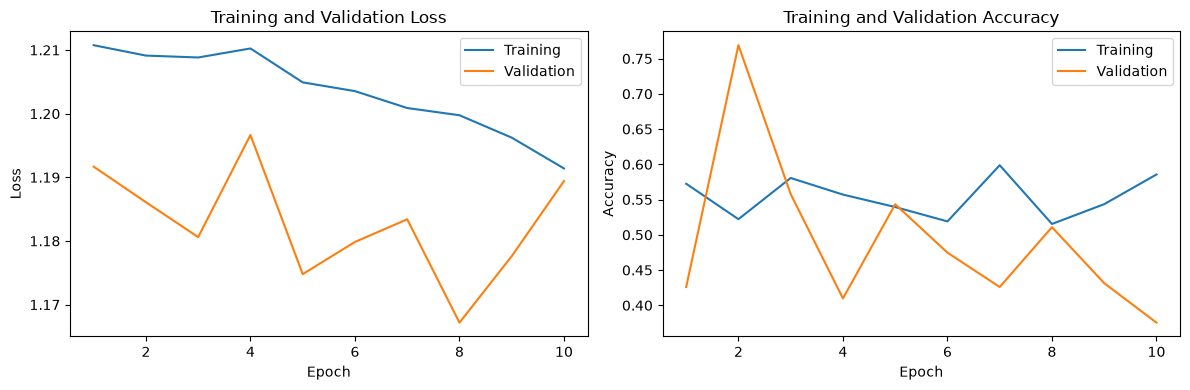

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = range(1, NUM_EPOCHS + 1)

# Loss
axes[0].plot(epochs, history["train_loss"], label="Training")
axes[0].plot(epochs, history["val_loss"], label="Validation")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Accuracy
axes[1].plot(epochs, history["train_accuracy"], label="Training")
axes[1].plot(epochs, history["val_accuracy"], label="Validation")
axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

## 07. Baseline Training Summary

A lightweight CNN with 3 convolutional layers was trained from randomly initialised weights.

- Training duration: 10 epochs
- Batch size: 32
- Optimiser: Adam
- Learning rate: 0.001
- Loss function: BCEWithLogitsLoss with training-derived positive class weighting
- Best checkpoint: Epoch 8
- Best validation loss: 1.1672

The model demonstrated limited improvement in training loss and fluctuating validation accuracy. This provides a baseline for comparison with subsequent ImageNet-pretrained ResNet18 model.

The best-performing checkpoint was saved as 'models/scratch_cnn_best.pth'.